In [14]:
import os, io, time, math, copy, warnings, platform, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
notebook_t0 = time.time()

In [15]:
stage = 1
use_drive = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {platform.python_version()} | torch {torch.__version__} | device: {device}")
if device.type == "cuda":
    print("GPU:",torch.cuda.get_device_name(0))
else:
    print("no gpu")

dgps   = ["linear","friedman1","friedman2","friedman3","rotated_sine","soft_radial"]
sizes  = [500,1000,2500,5000]
snrs   = [0.5,1,2,3]
n_test = 1000
base_seed = 42
models = ["OLS","RF","MLP","GBM","AttReg"]
model_label = {"OLS":"OLS","RF":"RF","MLP":"MLP","GBM":"GBM","AttReg":"Att Reg"}
dgp_label = {"linear": "Linear","friedman1":"Friedman 1","friedman2":"Friedman 2","friedman3":"Friedman 3","rotated_sine":"Rotated Sine","soft_radial":"Soft Radial"}

att_heads = 5
att_lambda = 1e-3
att_refit_lambda = 1e-5
att_refit_below = 0.1
att_max_steps = 300
att_lbfgs_max_iter = 20
att_lbfgs_history = 100
att_lr = 1.0
att_min_steps = 50
att_improve_tol= 1e-7
att_init_noise = 0.05

rf_trees, rf_mtry = 500,1/3
gbm_trees, gbm_lr = 500,0.01
mlp_layers, mlp_units = 3,200
mlp_dropout, mlp_lr = 0.2,1e-3
mlp_batch,mlp_max_epochs,mlp_patience,mlp_val_frac = 64,1000,20,0.15

if stage == 1:
    n_reps_max = 10
    main_budget_min = 50
    hard_stop_min = 55
    att_time_cap_s= 15
else:
    n_reps_max = 10
    main_budget_min = None
    hard_stop_min = None
    att_time_cap_s= None

if use_drive:
    from google.colab import drive
    drive.mount("/content/drive")
    out_dir = f"/content/drive/MyDrive/DA3410_A11_task3_stage{stage}"
else:
    out_dir = f"/content/A11_task3_stage{stage}" if os.path.isdir("/content") else f"./A11_task3_stage{stage}"
fig_dir = os.path.join(out_dir, "figures")
os.makedirs(fig_dir, exist_ok=True)
results_csv = os.path.join(out_dir, "results_long.csv")
print("Outputs go to:", out_dir)

colors = {"OLS":"#2a78d6","RF":"#eb6834","MLP":"#1baf7a","GBM":"#eda100","AttReg":"#e87ba4"}
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":160, "font.size":9.5,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.color":"#e6e6e3","grid.linewidth":0.6,"axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "legend.frameon": False})

def log_n_axis(ax):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator(sizes))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FixedFormatter([str(n) for n in sizes]))
    ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())

def savefig(fig, name):
    path = os.path.join(fig_dir,name)
    fig.savefig(path,bbox_inches="tight")
    print("saved",path)

Python 3.13.15 | torch 2.11.0+cu130 | device: cuda
GPU: Tesla T4
Outputs go to: /content/A11_task3_stage1


In [16]:
paper_table2 = """
dgp N snr OLS RF MLP GBM AttReg
linear 500 0.5 0.32 0.27 0.28 0.26 0.27
linear 500 1 0.49 0.43 0.45 0.44 0.45
linear 500 2 0.66 0.59 0.63 0.61 0.64
linear 500 3 0.75 0.67 0.72 0.70 0.73
linear 1000 0.5 0.32 0.27 0.31 0.28 0.29
linear 1000 1 0.49 0.44 0.47 0.45 0.42
linear 1000 2 0.66 0.60 0.64 0.62 0.55
linear 1000 3 0.74 0.68 0.73 0.71 0.68
linear 2500 0.5 0.32 0.29 0.31 0.30 0.27
linear 2500 1 0.49 0.46 0.48 0.47 0.43
linear 2500 2 0.66 0.62 0.65 0.64 0.55
linear 2500 3 0.74 0.70 0.74 0.72 0.65
linear 5000 0.5 0.34 0.31 0.33 0.32 0.26
linear 5000 1 0.50 0.47 0.49 0.48 0.38
linear 5000 2 0.67 0.64 0.66 0.65 0.52
linear 5000 3 0.75 0.72 0.75 0.73 0.57
friedman1 500 0.5 0.24 0.26 0.23 0.24 0.23
friedman1 500 1 0.36 0.41 0.42 0.41 0.42
friedman1 500 2 0.49 0.56 0.60 0.58 0.60
friedman1 500 3 0.55 0.63 0.69 0.66 0.71
friedman1 1000 0.5 0.25 0.27 0.29 0.27 0.30
friedman1 1000 1 0.37 0.42 0.45 0.43 0.47
friedman1 1000 2 0.50 0.58 0.62 0.59 0.64
friedman1 1000 3 0.56 0.66 0.71 0.67 0.73
friedman1 2500 0.5 0.24 0.28 0.29 0.28 0.31
friedman1 2500 1 0.36 0.44 0.46 0.44 0.48
friedman1 2500 2 0.49 0.60 0.63 0.60 0.64
friedman1 2500 3 0.55 0.68 0.72 0.68 0.72
friedman1 5000 0.5 0.25 0.30 0.32 0.30 0.33
friedman1 5000 1 0.37 0.46 0.48 0.45 0.48
friedman1 5000 2 0.49 0.62 0.65 0.61 0.64
friedman1 5000 3 0.55 0.70 0.73 0.68 0.72
friedman2 500 0.5 0.01 0.15 0.24 0.10 0.09
friedman2 500 1 0.03 0.26 0.40 0.21 0.37
friedman2 500 2 0.04 0.37 0.58 0.33 0.58
friedman2 500 3 0.05 0.42 0.67 0.37 0.67
friedman2 1000 0.5 0.02 0.18 0.27 0.12 0.23
friedman2 1000 1 0.04 0.30 0.44 0.23 0.41
friedman2 1000 2 0.05 0.42 0.61 0.34 0.57
friedman2 1000 3 0.06 0.49 0.70 0.40 0.63
friedman2 2500 0.5 0.02 0.23 0.30 0.17 0.26
friedman2 2500 1 0.04 0.36 0.46 0.29 0.41
friedman2 2500 2 0.05 0.50 0.63 0.40 0.57
friedman2 2500 3 0.06 0.57 0.72 0.45 0.66
friedman2 5000 0.5 0.04 0.26 0.31 0.20 0.27
friedman2 5000 1 0.05 0.41 0.47 0.30 0.41
friedman2 5000 2 0.07 0.55 0.64 0.41 0.52
friedman2 5000 3 0.08 0.63 0.73 0.46 0.63
friedman3 500 0.5 0.28 0.26 0.29 0.26 0.23
friedman3 500 1 0.44 0.41 0.46 0.43 0.44
friedman3 500 2 0.59 0.57 0.63 0.61 0.63
friedman3 500 3 0.67 0.64 0.72 0.70 0.72
friedman3 1000 0.5 0.30 0.27 0.30 0.29 0.31
friedman3 1000 1 0.45 0.43 0.47 0.46 0.48
friedman3 1000 2 0.60 0.59 0.64 0.63 0.65
friedman3 1000 3 0.67 0.67 0.73 0.71 0.74
friedman3 2500 0.5 0.29 0.28 0.31 0.31 0.32
friedman3 2500 1 0.44 0.45 0.48 0.47 0.49
friedman3 2500 2 0.59 0.61 0.65 0.64 0.65
friedman3 2500 3 0.67 0.70 0.73 0.72 0.74
friedman3 5000 0.5 0.29 0.29 0.31 0.31 0.31
friedman3 5000 1 0.44 0.46 0.48 0.47 0.48
friedman3 5000 2 0.59 0.63 0.65 0.64 0.65
friedman3 5000 3 0.66 0.71 0.73 0.72 0.74
rotated_sine 500 0.5 0.08 0.14 0.21 0.07 0.10
rotated_sine 500 1 0.13 0.25 0.38 0.15 0.33
rotated_sine 500 2 0.18 0.35 0.57 0.24 0.52
rotated_sine 500 3 0.21 0.40 0.66 0.29 0.61
rotated_sine 1000 0.5 0.10 0.18 0.27 0.12 0.21
rotated_sine 1000 1 0.15 0.30 0.43 0.20 0.37
rotated_sine 1000 2 0.20 0.42 0.61 0.30 0.51
rotated_sine 1000 3 0.23 0.48 0.70 0.35 0.56
rotated_sine 2500 0.5 0.10 0.23 0.30 0.15 0.23
rotated_sine 2500 1 0.15 0.36 0.46 0.25 0.34
rotated_sine 2500 2 0.20 0.50 0.63 0.34 0.50
rotated_sine 2500 3 0.22 0.56 0.72 0.39 0.57
rotated_sine 5000 0.5 0.10 0.26 0.30 0.16 0.22
rotated_sine 5000 1 0.16 0.40 0.47 0.26 0.36
rotated_sine 5000 2 0.21 0.54 0.64 0.35 0.47
rotated_sine 5000 3 0.24 0.61 0.73 0.40 0.58
soft_radial 500 0.5 -0.01 0.23 0.22 0.20 0.19
soft_radial 500 1 -0.01 0.37 0.41 0.33 0.36
soft_radial 500 2 -0.01 0.51 0.60 0.47 0.52
soft_radial 500 3 -0.01 0.58 0.68 0.54 0.61
soft_radial 1000 0.5 -0.00 0.26 0.27 0.23 0.21
soft_radial 1000 1 -0.00 0.40 0.45 0.36 0.38
soft_radial 1000 2 -0.00 0.55 0.62 0.49 0.55
soft_radial 1000 3 -0.00 0.62 0.70 0.56 0.63
soft_radial 2500 0.5 -0.00 0.28 0.30 0.25 0.28
soft_radial 2500 1 -0.00 0.43 0.47 0.38 0.43
soft_radial 2500 2 -0.00 0.59 0.64 0.51 0.55
soft_radial 2500 3 -0.00 0.66 0.72 0.58 0.65
soft_radial 5000 0.5 -0.00 0.29 0.31 0.25 0.29
soft_radial 5000 1 -0.00 0.45 0.48 0.39 0.45
soft_radial 5000 2 -0.00 0.61 0.65 0.52 0.56
soft_radial 5000 3 -0.00 0.69 0.73 0.59 0.62
"""
paper_wide = pd.read_csv(io.StringIO(paper_table2.strip()), sep=r"\s+")
paper_long = paper_wide.melt(id_vars=["dgp", "N", "snr"], var_name="model", value_name="r2_paper")
assert len(paper_wide) == 96
def paper_value(dgp, n, snr, model):
    r = paper_wide[(paper_wide.dgp == dgp) & (paper_wide.N == n) & (paper_wide.snr == snr)]
    return float(r[model].iloc[0])
print("Paper overall averages recomputed from Table 2 (paper text: OLS .28, RF .45, MLP .52, GBM .42, Att Reg .48):")
print(paper_wide[models].mean().round(3).to_string())

Paper overall averages recomputed from Table 2 (paper text: OLS .28, RF .45, MLP .52, GBM .42, Att Reg .48):
OLS       0.279
RF        0.454
MLP       0.521
GBM       0.418
AttReg    0.476


In [17]:
def simulate_data(n, dgp="linear", snr=1.0, seed=None):
    if seed is not None:
        np.random.seed(seed)
    X = np.random.uniform(0, 1, (n, 5))
    if dgp == "linear":
        y_pure = (X - 0.5) @ np.array([2, -1, 3, 1.5, 0.5])
    elif dgp == "friedman1":
        y_pure = 10*np.sin(np.pi*X[:, 0]*X[:, 1]) + 20*(X[:, 2]-0.5)**2 + 10*X[:, 3] + 5*X[:, 4]
    elif dgp == "friedman2":
        y_pure = np.sin(np.sum(X[:, :3], axis=1)*np.pi) + np.log(1 + X[:, 3]**2)
    elif dgp == "friedman3":
        y_pure = X[:, 0]*X[:, 1] + np.log(X[:, 2] + X[:, 3] + 2)
    elif dgp == "rotated_sine":
        y_pure = np.sin(3*np.sum(X[:, :4], axis=1))
    elif dgp == "soft_radial":
        y_pure = 1.0 / (1.0 + 5.0*np.sum((X - 0.5)**2, axis=1))
    else:
        raise ValueError(dgp)
    var_signal = np.var(y_pure) or 1.0
    y = y_pure + np.random.normal(0, np.sqrt(var_signal/snr), n)
    return X, y

def r2_max(snr):
    return snr/(snr+1)
rows = []
for d in dgps:
    X, y = simulate_data(20000, d, snr=1e12, seed=0)
    lin = LinearRegression().fit(X, y)
    rows.append({"DGP": dgp_label[d], "share of Var(f) explained by a linear fit": round(lin.score(X, y), 3)})
display(pd.DataFrame(rows).set_index("DGP"))
print("Multiply by R2_max to get the best OLS can do at a given SNR (e.g. Soft Radial: ~0, so OLS R2 ~ 0)")

,share of Var(f) explained by a linear fit
DGP,
Linear,1.000
Friedman 1,0.755
Friedman 2,0.099
Friedman 3,0.897
Rotated Sine,0.308
Soft Radial,0.000


Multiply by R2_max to get the best OLS can do at a given SNR (e.g. Soft Radial: ~0, so OLS R2 ~ 0)


In [18]:
def fit_ols(Xtr, ytr, Xte, seed=None):
    m = LinearRegression().fit(Xtr, ytr)
    return m.predict(Xte), m.predict(Xtr), {}

def fit_rf(Xtr, ytr, Xte, seed=None):
    m = RandomForestRegressor(n_estimators=rf_trees, max_features=rf_mtry, n_jobs=-1, random_state=seed).fit(Xtr, ytr)
    return m.predict(Xte), m.predict(Xtr), {}

def fit_gbm(Xtr, ytr, Xte, seed=None):
    m = GradientBoostingRegressor(n_estimators=gbm_trees, learning_rate=gbm_lr, random_state=seed).fit(Xtr, ytr)
    return m.predict(Xte), m.predict(Xtr), {}

class MLPNet(nn.Module):
    def __init__(self, p, units=mlp_units, layers=mlp_layers, dropout=mlp_dropout):
        super().__init__()
        mods, d = [], p
        for _ in range(layers):
            mods += [nn.Linear(d, units), nn.ReLU(), nn.Dropout(dropout)]
            d = units
        mods.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*mods)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def fit_mlp(Xtr, ytr, Xte, seed=None):
    sx = StandardScaler().fit(Xtr)
    Xs, Xts = sx.transform(Xtr), sx.transform(Xte)
    y_mean, y_std = ytr.mean(), ytr.std() + 1e-8
    ys = (ytr - y_mean) / y_std
    n = len(Xs); n_val = int(n * mlp_val_frac)
    if seed is not None:
        np.random.seed(seed)
    idx = np.random.permutation(n)
    va, tr = idx[:n_val], idx[n_val:]
    if seed is not None:
        torch.manual_seed(seed)
    T = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
    Xa, ya, Xv, yv = T(Xs[tr]), T(ys[tr]), T(Xs[va]), T(ys[va])
    model = MLPNet(Xs.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=mlp_lr)
    best, best_state, wait, epochs = float("inf"), None, 0, 0
    for epoch in range(mlp_max_epochs):
        model.train()
        perm = torch.randperm(len(Xa), device=device)
        for i in range(0, len(Xa), mlp_batch):
            b = perm[i:i + mlp_batch]
            opt.zero_grad(set_to_none=True)
            F.mse_loss(model(Xa[b]), ya[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = F.mse_loss(model(Xv), yv).item()
        epochs = epoch + 1
        if vl < best - 1e-6:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= mlp_patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p_te = model(T(Xts)).cpu().numpy() * y_std + y_mean
        p_tr = model(T(Xs)).cpu().numpy() * y_std + y_mean
    return p_te, p_tr, {"mlp_epochs": epochs}

In [19]:
use_sdpa = True
class AttentionRegressor(nn.Module):
    def __init__(self, M=5, P=5):
        super().__init__()
        self.M, self.P = M, P
        self.alpha = nn.Parameter(torch.ones(M) / M)
        self.L_params = nn.Parameter(torch.randn(M, P*(P+1)//2) * 0.1)
        tri = torch.tril_indices(P, P, offset=0)
        self.register_buffer("tri_r", tri[0])
        self.register_buffer("tri_c", tri[1])
        self.pad = 8 * math.ceil(P / 8)

    def get_L(self):
        L = self.L_params.new_zeros(self.M, self.P, self.P)
        L[:, self.tri_r, self.tri_c] = self.L_params
        return L

    @torch.no_grad()
    def init_from_ridge(self, X, lam):

        N = X.shape[0]
        XtX = (X.T @ X).double()
        inv = torch.linalg.inv(XtX + lam * torch.eye(self.P, dtype=torch.float64, device=X.device))
        Lt = (torch.linalg.cholesky(inv) * math.sqrt(N)).float()
        flat = Lt[self.tri_r, self.tri_c]
        for m in range(self.M):
            self.L_params.data[m] = flat + att_init_noise * torch.randn_like(flat)

    def attention_weights(self, X_train, X_query):
        L = self.get_L()
        Om = L @ L.transpose(1, 2)
        S = torch.einsum("qp,mpr,nr->mqn", X_query, Om, X_train)
        return torch.softmax(S, dim=-1)

    def head_predictions(self, X_train, y_train, X_query, use_sdpa=None):
        use_sdpa = use_sdpa if use_sdpa is None else use_sdpa
        if not use_sdpa:
            return self.attention_weights(X_train, X_query) @ y_train
        L = self.get_L()
        Q = torch.einsum("np,mpq->mnq", X_query, L)
        K = torch.einsum("np,mpq->mnq", X_train, L)
        if self.pad > self.P:
            Q = F.pad(Q, (0, self.pad - self.P)); K = F.pad(K, (0, self.pad - self.P))
        V = F.pad(y_train.view(1, -1, 1).expand(self.M, -1, 1), (0, self.pad - 1))
        out = F.scaled_dot_product_attention(Q.unsqueeze(0), K.unsqueeze(0), V.unsqueeze(0), scale=1.0)
        return out[0, :, :, 0]

    def forward(self, X_train, y_train, X_query=None, use_sdpa=None):
        Xq = X_train if X_query is None else X_query
        heads = self.head_predictions(X_train, y_train, Xq, use_sdpa)
        return (self.alpha.unsqueeze(1) * heads).sum(0)

def _fit_attention_once(Xtr, ytr, Xte, lam, seed, time_cap):
    if seed is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    y_mean, y_std = ytr.mean(), ytr.std() + 1e-8
    T = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
    Xt, yt, Xtt = T(Xtr), T((ytr - y_mean) / y_std), T(Xte)

    model = AttentionRegressor(M=att_heads, P=Xt.shape[1]).to(device)
    model.init_from_ridge(Xt, lam)
    opt = torch.optim.LBFGS(model.parameters(), lr=att_lr, max_iter=att_lbfgs_max_iter,
                            history_size=att_lbfgs_history, line_search_fn="strong_wolfe")
    n_evals = [0]
    def closure():
        opt.zero_grad()
        pred = model(Xt, yt)
        loss = torch.mean((pred - yt) ** 2) + lam * torch.sum(model.L_params ** 2)
        n_evals[0] += 1
        if not torch.isfinite(loss):
            return loss
        loss.backward()
        return loss

    t0, best, status, steps = time.time(), float("inf"), "max_steps", 0
    for step in range(att_max_steps):
        loss = float(opt.step(closure))
        steps = step + 1
        if not math.isfinite(loss):
            status = "nan"; break
        if loss < best - att_improve_tol:
            best = loss
        elif step > att_min_steps:
            status = "early_stop"; break
        if time_cap is not None and time.time() - t0 > time_cap:
            status = "time_cap"; break

    model.eval()
    with torch.no_grad():
        p_te = model(Xt, yt, Xtt).cpu().numpy() * y_std + y_mean
        p_tr = model(Xt, yt, Xt).cpu().numpy() * y_std + y_mean
    diag = {"att_steps": steps, "att_evals": n_evals[0], "att_status": status,
            "att_lambda": lam, "att_train_loss": best, "att_seconds": time.time() - t0}
    return p_te, p_tr, diag, model

def fit_attention(Xtr, ytr, Xte, yte=None, seed=None, time_cap=None, return_model=False):

    p_te, p_tr, diag, model = _fit_attention_once(Xtr, ytr, Xte, att_lambda, seed, time_cap)
    diag["att_refit"] = False
    if yte is not None:
        r2_first = r2_score(yte, p_te)
        diag["att_r2_first_fit"] = r2_first
        if r2_first < att_refit_below:
            p_te, p_tr, diag2, model = _fit_attention_once(Xtr, ytr, Xte, att_refit_lambda, seed, time_cap)
            diag.update(diag2); diag["att_refit"] = True
    return (p_te, p_tr, diag, model) if return_model else (p_te, p_tr, diag)
fitters = {"OLS": fit_ols, "RF": fit_rf, "MLP": fit_mlp, "GBM": fit_gbm}

In [20]:
X_chk, y_chk = simulate_data(700, "friedman1", 2, seed=1)
Xc = torch.tensor(X_chk, dtype=torch.float32, device=device)
yc = torch.tensor((y_chk - y_chk.mean()) / y_chk.std(), dtype=torch.float32, device=device)
torch.manual_seed(0)
m_chk = AttentionRegressor(5, 5).to(device); m_chk.init_from_ridge(Xc, att_lambda)
try:
    grads, preds = {}, {}
    for flag in (False, True):
        m_chk.zero_grad()
        p = m_chk(Xc, yc, use_sdpa=flag)
        loss = torch.mean((p - yc) ** 2) + att_lambda * torch.sum(m_chk.L_params ** 2)
        loss.backward()
        preds[flag] = p.detach().clone()
        grads[flag] = torch.cat([m_chk.L_params.grad.flatten(), m_chk.alpha.grad.flatten()]).clone()
    d_pred = (preds[True] - preds[False]).abs().max().item()
    d_grad = ((grads[True] - grads[False]).norm() / grads[False].norm()).item()
    use_sdpa = (d_pred < 1e-4) and (d_grad < 1e-3)
    print(f"max |pred diff| = {d_pred:.2e}, relative grad diff = {d_grad:.2e}  ->  USE_SDPA = {use_sdpa}")
except Exception as e:
    use_sdpa = False
    print("Fused kernel unavailable (", type(e).__name__, e, ") -> using the explicit formula.")

X_all, y_all = simulate_data(1500, "friedman1", 1, seed=3)
Z = np.column_stack([np.ones(len(X_all)), X_all])
Ztr, Zte, ytr_c = Z[:1000], Z[1000:], y_all[:1000]
lam_eig, U = np.linalg.eigh(Ztr.T @ Ztr)
Ftr, Fte = Ztr @ U / np.sqrt(lam_eig), Zte @ U / np.sqrt(lam_eig)
W_ols = Fte @ Ftr.T
yhat_att = W_ols @ ytr_c
yhat_ols = LinearRegression(fit_intercept=False).fit(Ztr, ytr_c).predict(Zte)
print(f"\nmax |OLS - attention form| = {np.abs(yhat_att - yhat_ols).max():.2e}")
print(f"||F_train'F_train - I|| = {np.linalg.norm(Ftr.T @ Ftr - np.eye(6)):.2e}   (identity on the training set)")
print(f"||F_test'F_test  - I|| = {np.linalg.norm(Fte.T @ Fte - np.eye(6)):.2f}       (not the identity out of sample)")
print(f"OLS weight rows sum to 1: max |row sum - 1| = {np.abs(W_ols.sum(1) - 1).max():.2e}; "
      f"share of negative weights = {(W_ols < 0).mean():.2f}  (softmax attention can never produce these)")

Om0 = (m_chk.get_L() @ m_chk.get_L().transpose(1, 2)).detach().double().cpu().numpy()
target = 700 * np.linalg.inv(X_chk.T @ X_chk + att_lambda * np.eye(5))
print(f"\nInitial Omega_m vs N(X'X+lambda I)^-1, relative difference per head: "
      f"{[round(float(np.linalg.norm(Om0[m]-target)/np.linalg.norm(target)), 3) for m in range(5)]}  (noise only)")

max |pred diff| = 4.77e-07, relative grad diff = 1.83e-07  ->  USE_SDPA = True

max |OLS - attention form| = 5.51e-14
||F_train'F_train - I|| = 1.13e-14   (identity on the training set)
||F_test'F_test  - I|| = 1.23       (not the identity out of sample)
OLS weight rows sum to 1: max |row sum - 1| = 5.77e-15; share of negative weights = 0.33  (softmax attention can never produce these)

Initial Omega_m vs N(X'X+lambda I)^-1, relative difference per head: [0.048, 0.028, 0.042, 0.032, 0.03]  (noise only)


In [21]:
def run_condition(dgp, n, snr, rep, verbose=False):
    seed = base_seed + rep * 1000
    X, y = simulate_data(n + n_test, dgp, snr, seed=seed)
    Xtr, ytr, Xte, yte = X[:n], y[:n], X[n:], y[n:]
    rows = []
    for name in models:
        t0 = time.time()
        if name == "AttReg":
            p_te, p_tr, extra = fit_attention(Xtr, ytr, Xte, yte, seed=seed, time_cap=att_time_cap_s)
        else:
            p_te, p_tr, extra = fitters[name](Xtr, ytr, Xte, seed=seed)
        rows.append({"dgp": dgp, "N": n, "snr": snr, "rep": rep, "model": name,
                     "r2_test": r2_score(yte, p_te), "r2_train": r2_score(ytr, p_tr),
                     "fit_s": time.time() - t0, **extra})
    return rows

t0 = time.time()
smoke = pd.DataFrame(run_condition("friedman1", 500, 1, rep=0))
smoke["paper"] = [paper_value("friedman1", 500, 1, m) for m in smoke.model]
display(smoke[["model", "r2_test", "paper", "r2_train", "fit_s"]].round(3))
a = smoke[smoke.model == "AttReg"].iloc[0]
print(f"Attention: {a.att_status} after {a.att_steps} L-BFGS steps ({a.att_evals} loss evaluations), refit = {a.att_refit}")
print(f"Smoke test took {time.time()-t0:.1f}s (one replication of one condition; paper values are 10-rep averages)")
Xb, yb = simulate_data(5000, "friedman1", 1, seed=5)
Xb_t = torch.tensor(Xb, dtype=torch.float32, device=device)
yb_t = torch.tensor((yb - yb.mean()) / yb.std(), dtype=torch.float32, device=device)
mb = AttentionRegressor(5, 5).to(device); mb.init_from_ridge(Xb_t, att_lambda)
for i in range(6):
    if i == 1:
        if device.type == "cuda": torch.cuda.synchronize()
        tb = time.time()
    mb.zero_grad(); (torch.mean((mb(Xb_t, yb_t) - yb_t) ** 2)).backward()
if device.type == "cuda": torch.cuda.synchronize()
print(f"One loss+gradient evaluation at N=5000: {(time.time()-tb)/5*1000:.1f} ms")
del mb, Xb_t, yb_t
if device.type == "cuda": torch.cuda.empty_cache()

,model,r2_test,paper,r2_train,fit_s
0,OLS,0.346,0.36,0.376,0.011
1,RF,0.385,0.41,0.919,2.461
2,MLP,0.398,0.42,0.570,0.995
3,GBM,0.381,0.41,0.682,1.338
4,AttReg,0.419,0.42,0.559,15.221


Attention: time_cap after 53.0 L-BFGS steps (1224.0 loss evaluations), refit = False
Smoke test took 20.0s (one replication of one condition; paper values are 10-rep averages)
One loss+gradient evaluation at N=5000: 38.0 ms


In [22]:
keys = [(d, n, s) for d in dgps for n in sizes for s in snrs]
def load_done():
    if not os.path.exists(results_csv):
        return set()
    prev = pd.read_csv(results_csv)
    cnt = prev.groupby(["dgp", "N", "snr", "rep"]).model.nunique()
    return {k for k, v in cnt.items() if v == len(models)}

result_columns = ["dgp", "N", "snr", "rep", "model", "r2_test", "r2_train", "fit_s", "mlp_epochs","att_steps", "att_evals", "att_status", "att_lambda", "att_train_loss", "att_seconds","att_refit", "att_r2_first_fit"]

def append_rows(rows):
    df = pd.DataFrame(rows).reindex(columns=result_columns)
    df.to_csv(results_csv, mode="a", header=not os.path.exists(results_csv), index=False)

def fmt_min(s):
    return f"{int(s//60):02d}:{int(s%60):02d}"

done = load_done()
print(f"Already done: {len(done)} condition-replications. Stage {stage}: up to {n_reps_max} replications, "
      f"budget {main_budget_min} min, attention cap {att_time_cap_s} s per fit.\n")
loop_t0, rep_times, stopped = time.time(), [], False
budget_s = None if main_budget_min is None else main_budget_min * 60
hard_s = None if hard_stop_min is None else hard_stop_min * 60

for rep in range(n_reps_max):
    todo = [k for k in keys if (k[0], k[1], k[2], rep) not in done]
    if not todo:
        continue
    elapsed = time.time() - loop_t0
    if budget_s is not None and rep_times:
        projected = elapsed + 1.05 * np.mean(rep_times) * len(todo) / len(keys)
        if projected > budget_s:
            print(f"\nStopping before replication {rep}: projected finish {fmt_min(projected)} > budget {fmt_min(budget_s)}.")
            break
    print(f"replication {rep} ({len(todo)} conditions)")
    t_rep = time.time()
    for (dgp, n, snr) in todo:
        if hard_s is not None and time.time() - loop_t0 > hard_s:
            print("Hard stop reached; replication left incomplete."); stopped = True; break
        tc = time.time()
        rows = run_condition(dgp, n, snr, rep)
        append_rows(rows)
        r = {x["model"]: x for x in rows}
        att = r["AttReg"]
        print(f"[r{rep}] {dgp_label[dgp]:<12} N={n:<5} SNR={snr:<3} | "
              + " ".join(f"{model_label[m]} {r[m]['r2_test']:+.2f}" for m in models)
              + f" (paper Att {paper_value(dgp, n, snr, 'AttReg'):.2f}) | att {att['att_status']}"
              + f"{' refit' if att['att_refit'] else ''} {att['att_steps']} st | {time.time()-tc:5.1f}s | "
              + f"total {fmt_min(time.time()-loop_t0)}", flush=True)
    if stopped:
        break
    if len(todo) == len(keys):
        rep_times.append(time.time() - t_rep)
    print(f"replication {rep} done in {fmt_min(time.time()-t_rep)}\n")

res = pd.read_csv(results_csv)
n_reps = res.groupby(["dgp", "N", "snr"]).rep.nunique()
print(f"\nMain loop finished in {fmt_min(time.time()-loop_t0)}. Conditions covered: {len(n_reps)}/96, "
      f"replications per condition: min {n_reps.min()}, max {n_reps.max()}.")

Already done: 0 condition-replications. Stage 1: up to 10 replications, budget 50 min, attention cap 15 s per fit.

replication 0 (96 conditions)
[r0] Linear       N=500   SNR=0.5 | OLS +0.34 RF +0.27 MLP +0.32 GBM +0.25 Att Reg +0.31 (paper Att 0.27) | att time_cap 55 st |  17.4s | total 00:17
[r0] Linear       N=500   SNR=1   | OLS +0.50 RF +0.42 MLP +0.46 GBM +0.42 Att Reg +0.47 (paper Att 0.45) | att time_cap 55 st |  17.9s | total 00:35
[r0] Linear       N=500   SNR=2   | OLS +0.66 RF +0.57 MLP +0.63 GBM +0.60 Att Reg +0.62 (paper Att 0.64) | att time_cap 54 st |  18.2s | total 00:53
[r0] Linear       N=500   SNR=3   | OLS +0.74 RF +0.65 MLP +0.71 GBM +0.69 Att Reg +0.72 (paper Att 0.73) | att time_cap 51 st |  17.5s | total 01:10
[r0] Linear       N=1000  SNR=0.5 | OLS +0.31 RF +0.27 MLP +0.29 GBM +0.27 Att Reg +0.30 (paper Att 0.29) | att early_stop 52 st |   9.0s | total 01:19
[r0] Linear       N=1000  SNR=1   | OLS +0.49 RF +0.44 MLP +0.47 GBM +0.45 Att Reg +0.48 (paper Att 0.

In [23]:
res = pd.read_csv(results_csv)
cond = (res.groupby(["dgp", "N", "snr", "model"])
           .agg(r2=("r2_test", "mean"), sd=("r2_test", "std"), reps=("rep", "nunique"),
                r2_train=("r2_train", "mean"), fit_s=("fit_s", "mean"))
           .reset_index())
cmp = paper_long.merge(cond, on=["dgp", "N", "snr", "model"], how="left")
cmp["diff"] = cmp.r2 - cmp.r2_paper
cmp["se"] = cmp.sd / np.sqrt(cmp.reps)
cmp["dgp"] = pd.Categorical(cmp.dgp, dgps, ordered=True)
cmp["model"] = pd.Categorical(cmp.model, models, ordered=True)
cmp = cmp.sort_values(["dgp", "N", "snr", "model"]).reset_index(drop=True)
cmp.to_csv(os.path.join(out_dir, "condition_means_vs_paper.csv"), index=False)
print(f"{cmp.r2.notna().sum()}/{len(cmp)} model-condition cells filled; replications per condition: "
      f"{int(cmp.reps.min())}-{int(cmp.reps.max())}")

def group_summary(df, value):
    per_dgp = df.groupby(["dgp", "model"], observed=True)[value].mean().unstack()[models]
    per_dgp.index = [dgp_label[d] for d in per_dgp.index]
    overall = df.groupby("model", observed=True)[value].mean()[models].to_frame("Overall").T
    return pd.concat([overall, per_dgp])
ours_sum, paper_sum = group_summary(cmp, "r2"), group_summary(cmp, "r2_paper")
headline = pd.concat({"Ours": ours_sum, "Paper": paper_sum}, axis=1).round(3)
headline.columns = pd.MultiIndex.from_tuples([(a, model_label[b]) for a, b in headline.columns])
headline.to_csv(os.path.join(out_dir, "table_overall_and_per_dgp.csv"))
print("\nAverage out-of-sample R2 (Overall = mean over the 96 conditions; each DGP = mean over its 16 conditions)")
display(headline)

480/480 model-condition cells filled; replications per condition: 1-1

Average out-of-sample R2 (Overall = mean over the 96 conditions; each DGP = mean over its 16 conditions)


Ours                               Paper                       \
                OLS     RF    MLP    GBM Att Reg    OLS     RF    MLP    GBM   
Overall       0.288  0.455  0.530  0.418   0.479  0.279  0.454  0.521  0.418   
Linear        0.561  0.507  0.544  0.523   0.484  0.556  0.510  0.540  0.524   
Friedman 1    0.425  0.494  0.524  0.497   0.518  0.414  0.492  0.518  0.493   
Friedman 2    0.045  0.373  0.522  0.287   0.482  0.044  0.381  0.511  0.299   
Friedman 3    0.507  0.501  0.545  0.526   0.548  0.498  0.498  0.536  0.523   
Rotated Sine  0.191  0.378  0.519  0.258   0.370  0.166  0.374  0.505  0.251   
Soft Radial  -0.004  0.479  0.528  0.416   0.471 -0.002  0.470  0.516  0.416   

                      
             Att Reg  
Overall        0.476  
Linear         0.479  
Friedman 1     0.526  
Friedman 2     0.455  
Friedman 3     0.536  
Rotated Sine   0.405  
Soft Radial    0.455

In [24]:
wide_ours = cmp.pivot_table(index=["dgp", "N", "snr"], columns="model", values="r2", observed=True)[models]
wide_paper = cmp.pivot_table(index=["dgp", "N", "snr"], columns="model", values="r2_paper", observed=True)[models]
table2 = pd.concat({"Ours": wide_ours, "Paper": wide_paper}, axis=1)
table2.index = table2.index.set_levels([dgp_label[d] for d in table2.index.levels[0]], level=0)
table2.to_csv(os.path.join(out_dir, "table2_ours_vs_paper.csv"))

def bold_best(row):
    out = []
    for block in ("Ours", "Paper"):
        vals = row[block]
        best = vals.max()
        out += ["font-weight:bold; background-color:#dff3ea" if v == best else "" for v in vals]
    return out
display(table2.style.format("{:.2f}").apply(bold_best, axis=1).set_caption("Out-of-sample R2 per condition (best model of each row highlighted, separately for ours and the paper)"))

saved /content/A11_task3_stage1/figures/fig1_figure2.png


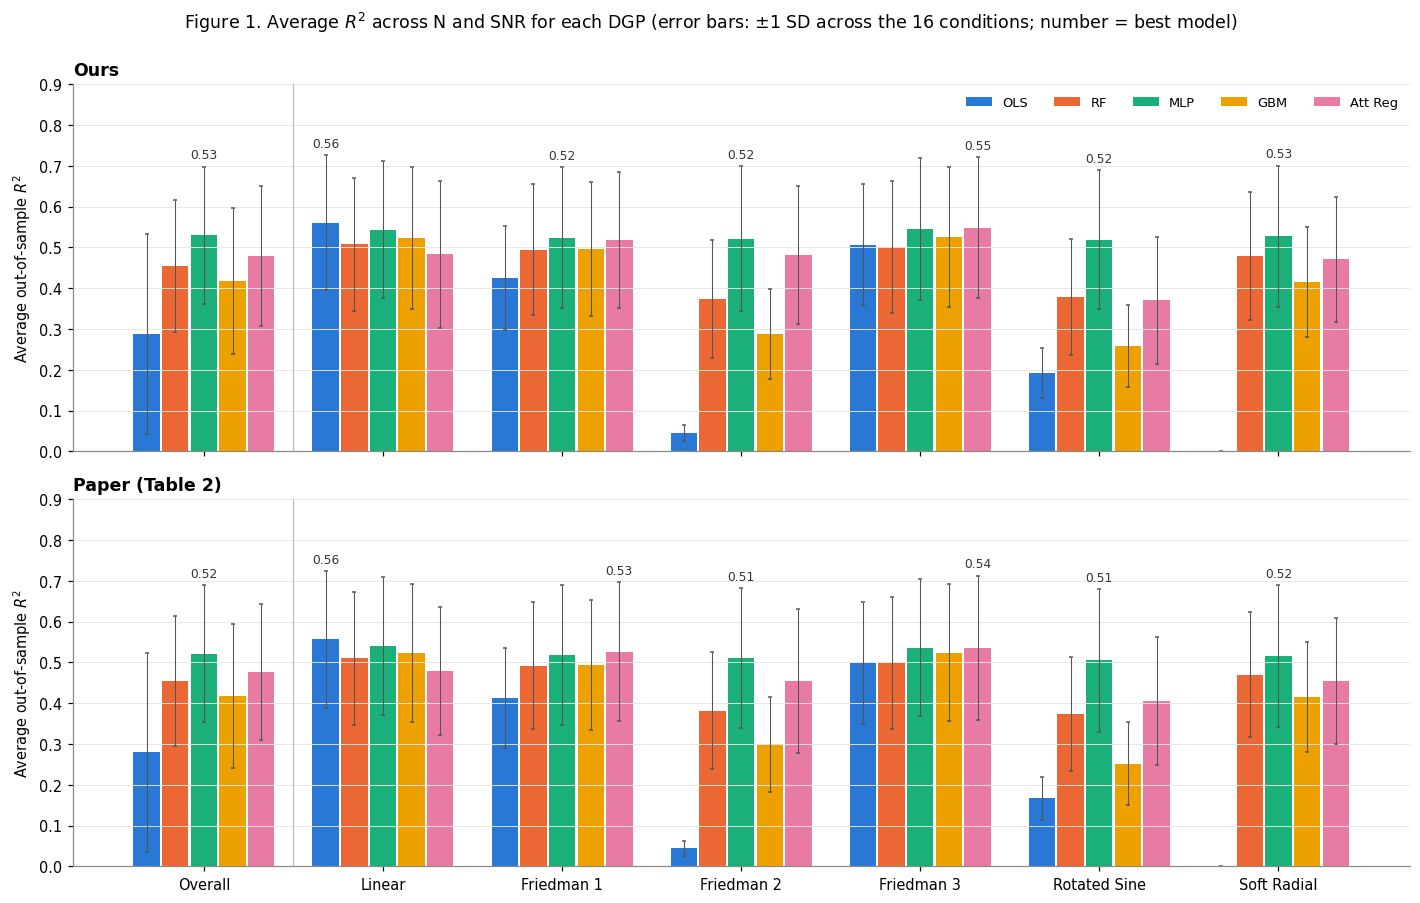

In [25]:
def fig2_stats(df, value):
    groups = ["Overall"] + dgps
    mean, sd = {}, {}
    for g in groups:
        sub = df if g == "Overall" else df[df.dgp == g]
        per_cond = sub.pivot_table(index=["dgp", "N", "snr"], columns="model", values=value, observed=True)
        mean[g], sd[g] = per_cond.mean(), per_cond.std()
    return groups, mean, sd

fig, axes = plt.subplots(2, 1, figsize=(13, 8.2), sharex=True, sharey=True)
for ax, value, title in [(axes[0], "r2", "Ours"), (axes[1], "r2_paper", "Paper (Table 2)")]:
    groups, mean, sd = fig2_stats(cmp, value)
    w = 0.16
    for k, m in enumerate(models):
        x = np.arange(len(groups)) + (k - 2) * w
        ax.bar(x, [mean[g][m] for g in groups], w * 0.92, yerr=[sd[g][m] for g in groups],
               color=colors[m], label=model_label[m], capsize=1.5, error_kw={"elinewidth": 0.7, "ecolor": "#555"})
    for j, g in enumerate(groups):
        best = mean[g].idxmax()
        ax.text(j + (models.index(best) - 2) * w, mean[g][best] + sd[g][best] + 0.02, f"{mean[g][best]:.2f}",
                ha="center", fontsize=8, color="#333")
    ax.axvline(0.5, color="#bbb", lw=0.8)
    ax.set_ylim(0, 0.9); ax.set_title(title, loc="left"); ax.grid(axis="x", visible=False)
    ax.set_ylabel("Average out-of-sample $R^2$")
axes[1].set_xticks(np.arange(len(groups)))
axes[1].set_xticklabels(["Overall"] + [dgp_label[d] for d in dgps])
axes[0].legend(loc="upper right", ncol=5, fontsize=8.5)
fig.suptitle("Figure 1. Average $R^2$ across N and SNR for each DGP (error bars: ±1 SD across the 16 conditions; number = best model)", y=0.995)
fig.tight_layout()
savefig(fig, "fig1_figure2.png")
plt.show()

saved /content/A11_task3_stage1/figures/fig2.png


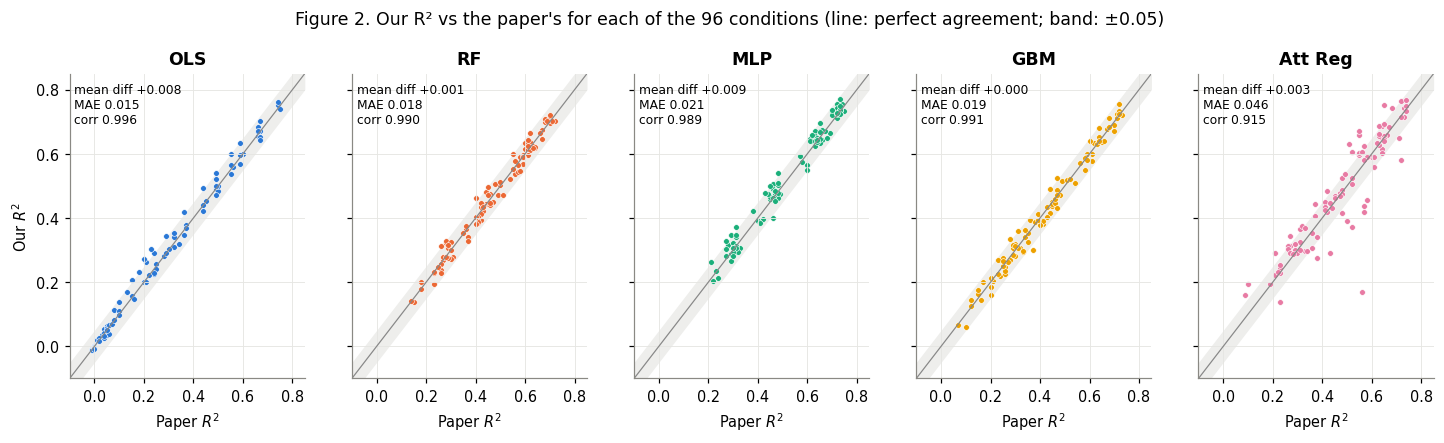

In [26]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True, sharey=True)
for ax, m in zip(axes, models):
    sub = cmp[(cmp.model == m) & cmp.r2.notna()]
    ax.fill_between([-0.1, 0.85], [-0.15, 0.80], [-0.05, 0.90], color="#eeeeec", lw=0)
    ax.plot([-0.1, 0.85], [-0.1, 0.85], color="#888", lw=0.8)
    ax.scatter(sub.r2_paper, sub.r2, s=14, color=colors[m], edgecolor="white", linewidth=0.4)
    mae, bias = sub["diff"].abs().mean(), sub["diff"].mean()
    corr = np.corrcoef(sub.r2_paper, sub.r2)[0, 1] if len(sub) > 2 else np.nan
    ax.set_title(model_label[m])
    ax.text(0.02, 0.97, f"mean diff {bias:+.3f}\nMAE {mae:.3f}\ncorr {corr:.3f}", transform=ax.transAxes,
            va="top", fontsize=8)
    ax.set_xlabel("Paper $R^2$")
axes[0].set_ylabel("Our $R^2$")
axes[0].set_xlim(-0.1, 0.85); axes[0].set_ylim(-0.1, 0.85)
fig.suptitle("Figure 2. Our R² vs the paper's for each of the 96 conditions (line: perfect agreement; band: ±0.05)", y=1.04)
savefig(fig, "fig2.png")
plt.show()

saved /content/A11_task3_stage1/figures/fig3_heatmap.png


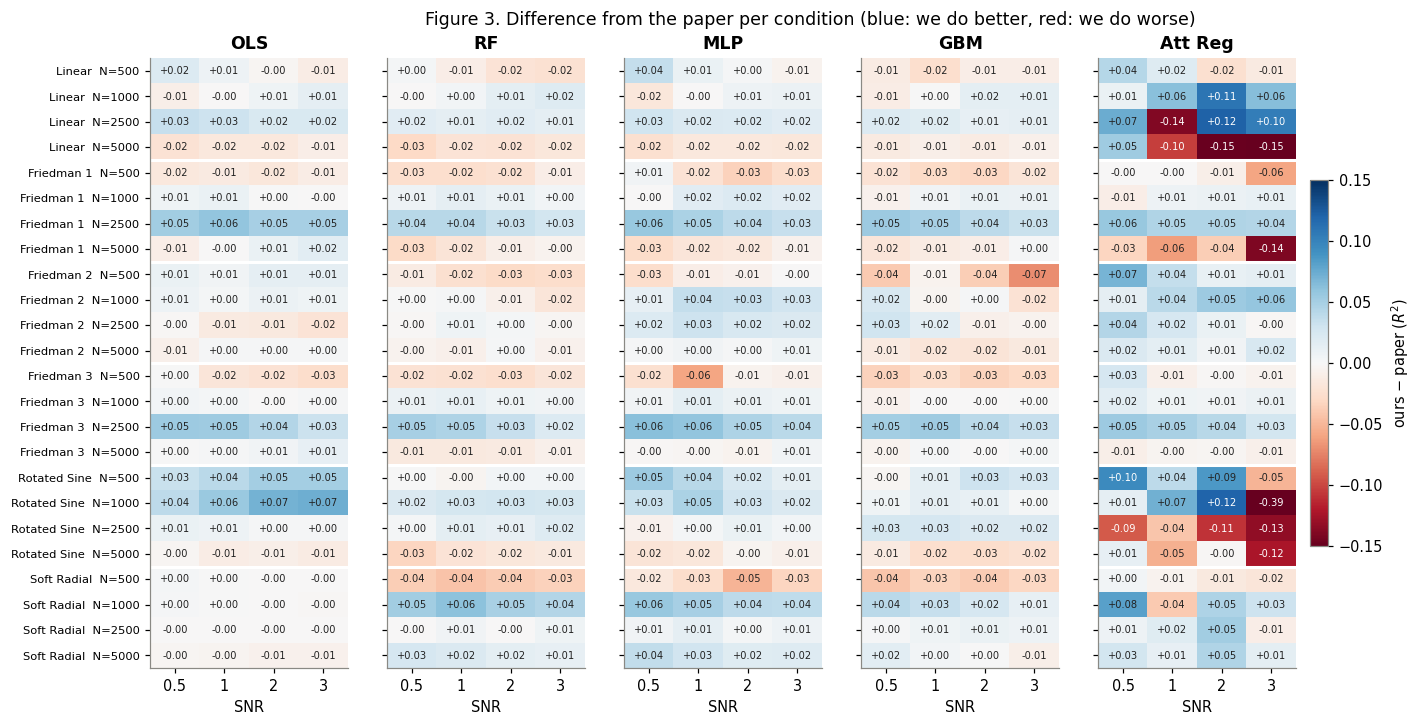

In [27]:
fig, axes = plt.subplots(1, 5, figsize=(16, 7.2), sharey=True)
row_labels = [f"{dgp_label[d]}  N={n}" for d in dgps for n in sizes]
for ax, m in zip(axes, models):
    mat = (cmp[cmp.model == m].pivot_table(index=["dgp", "N"], columns="snr", values="diff", observed=True)
              .reindex(pd.MultiIndex.from_product([dgps, sizes])).values)
    im = ax.imshow(mat, cmap="RdBu", vmin=-0.15, vmax=0.15, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if np.isfinite(mat[i, j]):
                ax.text(j, i, f"{mat[i, j]:+.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if abs(mat[i, j]) > 0.09 else "#222")
    ax.set_xticks(range(len(snrs))); ax.set_xticklabels(snrs); ax.set_xlabel("SNR")
    ax.set_title(model_label[m]); ax.grid(False)
    for b in range(1, len(dgps)):
        ax.axhline(b * len(sizes) - 0.5, color="white", lw=2)
axes[0].set_yticks(range(len(row_labels))); axes[0].set_yticklabels(row_labels, fontsize=7.5)
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.01); cb.set_label("ours − paper ($R^2$)")
fig.suptitle("Figure 3. Difference from the paper per condition (blue: we do better, red: we do worse)", y=0.94)
savefig(fig, "fig3_heatmap.png")
plt.show()

saved /content/A11_task3_stage1/figures/fig4.png


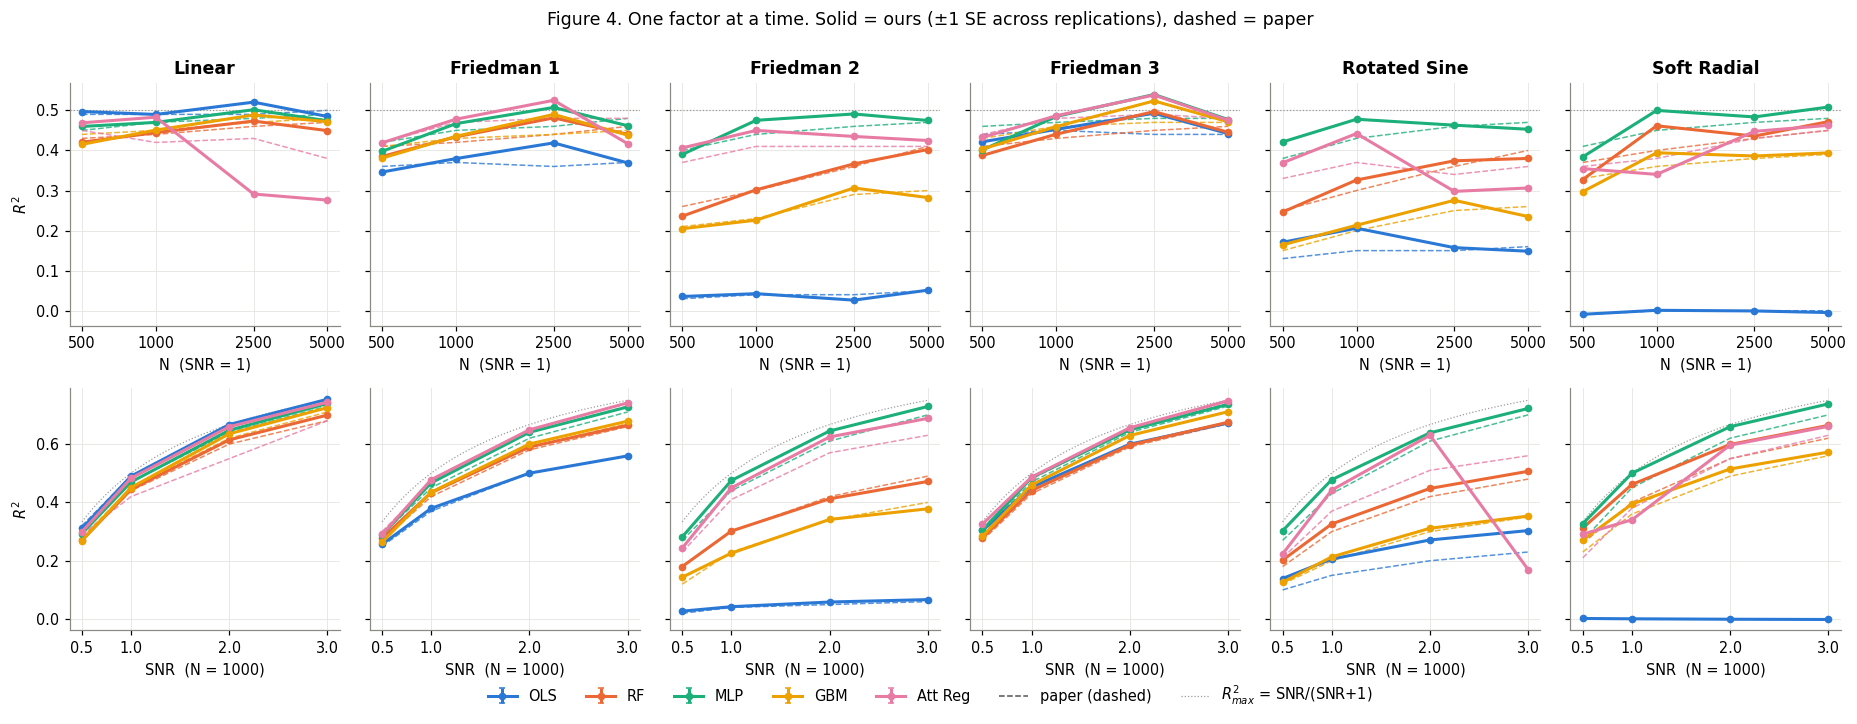

In [28]:
fix_snr, fix_n = 1, 1000
fig, axes = plt.subplots(2, 6, figsize=(17, 6.2), sharey="row")
for j, d in enumerate(dgps):
    for row, (fac, fixed_col, fixed_val) in enumerate([("N", "snr", fix_snr), ("snr", "N", fix_n)]):
        ax = axes[row, j]
        sub = cmp[(cmp.dgp == d) & (cmp[fixed_col] == fixed_val)].sort_values(fac)
        for m in models:
            s = sub[sub.model == m]
            ax.plot(s[fac], s.r2_paper, color=colors[m], lw=1, ls="--", alpha=0.8)
            ax.errorbar(s[fac], s.r2, yerr=s.se.fillna(0), color=colors[m], lw=2, marker="o", ms=4,
                        capsize=2, label=model_label[m])
        if fac == "N":
            log_n_axis(ax)
            ax.axhline(r2_max(fix_snr), color="#999", lw=0.8, ls=":")
            ax.set_xlabel(f"N  (SNR = {fix_snr})")
        else:
            xs = np.linspace(0.5, 3, 50)
            ax.plot(xs, r2_max(xs), color="#999", lw=0.8, ls=":")
            ax.set_xticks(snrs); ax.set_xlabel(f"SNR  (N = {fix_n})")
        if row == 0:
            ax.set_title(dgp_label[d])
axes[0, 0].set_ylabel("$R^2$"); axes[1, 0].set_ylabel("$R^2$")
h, l = axes[0, 0].get_legend_handles_labels()
h += [plt.Line2D([], [], color="#555", lw=1, ls="--"), plt.Line2D([], [], color="#999", lw=0.8, ls=":")]
l += ["paper (dashed)", "$R^2_{max}$ = SNR/(SNR+1)"]
fig.legend(h, l, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Figure 4. One factor at a time. Solid = ours (±1 SE across replications), dashed = paper", y=1.0)
fig.tight_layout()
savefig(fig, "fig4.png")
plt.show()

,wins (ours),wins (paper),mean rank (ours),mean rank (paper)
OLS,17,16,4.12,4.16
RF,0,2,3.40,3.30
MLP,55,61,1.55,1.48
GBM,0,0,3.72,3.61
Att Reg,24,17,2.21,2.44


Note: paper values are rounded to 2 decimals, so ties are common there; ties count for the first model in column order.
saved /content/A11_task3_stage1/figures/fig5.png


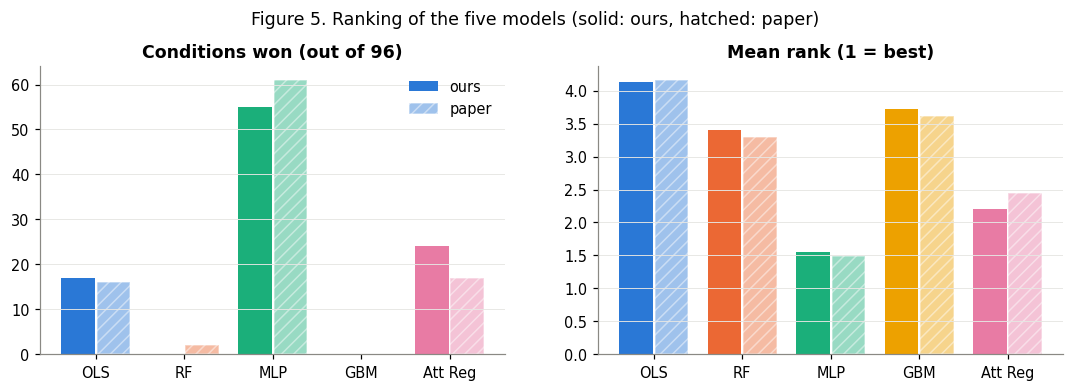

In [29]:
def winners(value):
    w = cmp.pivot_table(index=["dgp", "N", "snr"], columns="model", values=value, observed=True)[models]
    w = w.dropna()
    ranks = w.rank(axis=1, ascending=False, method="average")
    return w.idxmax(axis=1).value_counts().reindex(models, fill_value=0), ranks.mean()
win_o, rank_o = winners("r2"); win_p, rank_p = winners("r2_paper")
wins = pd.DataFrame({"wins (ours)": win_o, "wins (paper)": win_p,
                     "mean rank (ours)": rank_o.round(2), "mean rank (paper)": rank_p.round(2)})
wins.index = [model_label[m] for m in wins.index]
display(wins)
print("Note: paper values are rounded to 2 decimals, so ties are common there; ties count for the first model in column order.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
x = np.arange(len(models))
for ax, (a, b, title) in zip(axes, [(win_o, win_p, "Conditions won (out of 96)"), (rank_o, rank_p, "Mean rank (1 = best)")]):
    ax.bar(x - 0.2, a.values, 0.38, color=[colors[m] for m in models], label="ours")
    ax.bar(x + 0.2, b.values, 0.38, color=[colors[m] for m in models], alpha=0.45, hatch="///", edgecolor="white", label="paper")
    ax.set_xticks(x); ax.set_xticklabels([model_label[m] for m in models]); ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].legend()
fig.suptitle("Figure 5. Ranking of the five models (solid: ours, hatched: paper)", y=1.03)
savefig(fig,"fig5.png")
plt.show()

saved /content/A11_task3_stage1/figures/fig6_diagnostics.png


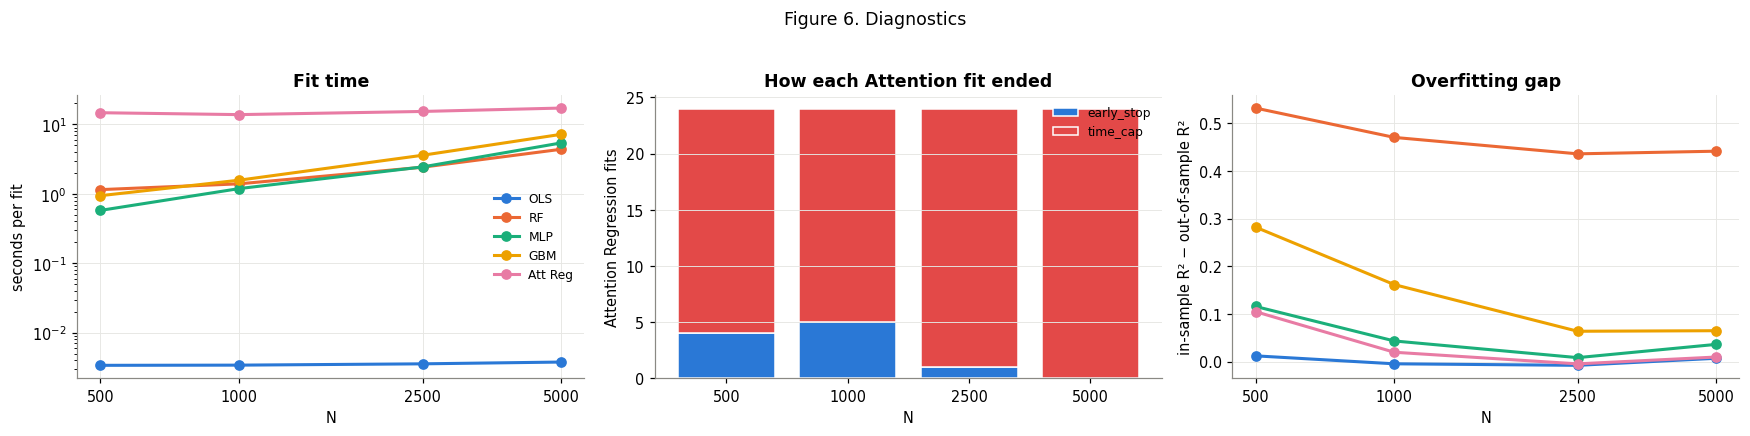

Attention Regression fits:
  status counts: {'time_cap': 86, 'early_stop': 10}
  refits with lambda=1e-5: 9 of 96
  L-BFGS steps: median 50, max 55; loss evaluations: median 824
  mean R2 of capped vs uncapped fits: {'not capped': 0.367, 'capped': 0.492}


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
t = res.groupby(["model", "N"]).fit_s.mean().unstack(0)[models]
for m in models:
    axes[0].plot(t.index, t[m], marker="o", color=colors[m], lw=2, label=model_label[m])
log_n_axis(axes[0]); axes[0].set_yscale("log")
axes[0].set_xlabel("N"); axes[0].set_ylabel("seconds per fit"); axes[0].set_title("Fit time"); axes[0].legend(fontsize=8)

att = res[res.model == "AttReg"].copy()
st = att.groupby(["N", "att_status"]).size().unstack(fill_value=0)
bottom = np.zeros(len(st))
status_col = {"early_stop": "#2a78d6", "max_steps": "#eda100", "time_cap": "#e34948", "nan": "#6250d6"}
for s in st.columns:
    axes[1].bar([str(n) for n in st.index], st[s].values, bottom=bottom, color=status_col.get(s, "#999"), label=s,
                edgecolor="white", linewidth=1)
    bottom += st[s].values
axes[1].set_xlabel("N"); axes[1].set_ylabel("Attention Regression fits"); axes[1].legend(fontsize=8)
axes[1].set_title("How each Attention fit ended"); axes[1].grid(axis="x", visible=False)

gap = (res.assign(gap=res.r2_train - res.r2_test).groupby(["model", "N"]).gap.mean().unstack(0)[models])
for m in models:
    axes[2].plot(gap.index, gap[m], marker="o", color=colors[m], lw=2, label=model_label[m])
log_n_axis(axes[2])
axes[2].set_xlabel("N"); axes[2].set_ylabel("in-sample R² − out-of-sample R²"); axes[2].set_title("Overfitting gap")
fig.suptitle("Figure 6. Diagnostics", y=1.03)
fig.tight_layout(); savefig(fig, "fig6_diagnostics.png"); plt.show()

print("Attention Regression fits:")
print(f"  status counts: {att.att_status.value_counts().to_dict()}")
print(f"  refits with lambda=1e-5: {int(att.att_refit.astype(bool).sum())} of {len(att)}")
print(f"  L-BFGS steps: median {att.att_steps.median():.0f}, max {att.att_steps.max():.0f}; "
      f"loss evaluations: median {att.att_evals.median():.0f}")
if (att.att_status == "time_cap").any():
    print("  mean R2 of capped vs uncapped fits:",
          att.groupby(att.att_status == "time_cap").r2_test.mean().rename({True: "capped", False: "not capped"}).round(3).to_dict())

saved /content/A11_task3_stage1/figures/fig7_attention_weights.png


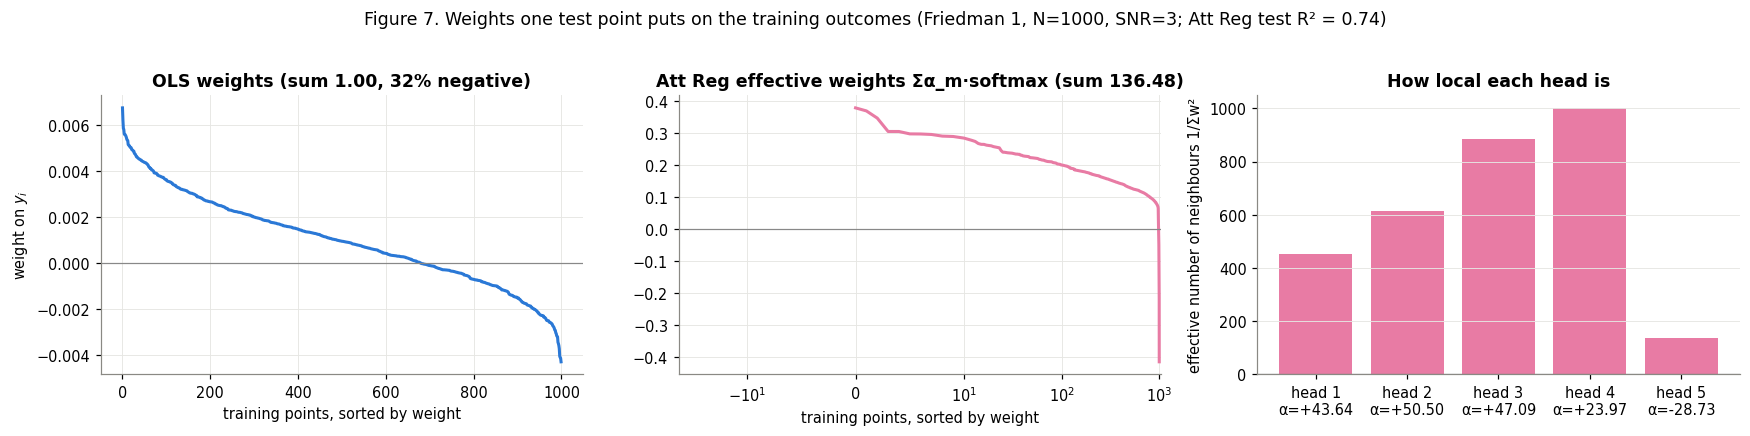

Each softmax head gives non-negative weights summing to 1; heads are combined with unconstrained alphas


In [31]:
d0, n0, s0 = "friedman1", 1000, 3
X, y = simulate_data(n0 + n_test, d0, s0, seed=base_seed)
Xtr, ytr, Xte, yte = X[:n0], y[:n0], X[n0:], y[n0:]
p_te, _, diag0, model0 = fit_attention(Xtr, ytr, Xte, yte, seed=base_seed, time_cap=att_time_cap_s, return_model=True)
Ztr, Zte = np.column_stack([np.ones(n0), Xtr]), np.column_stack([np.ones(n_test), Xte])
W_ols = Zte @ np.linalg.solve(Ztr.T @ Ztr, Ztr.T)
with torch.no_grad():
    T = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
    A = model0.attention_weights(T(Xtr), T(Xte[:1])).cpu().numpy()[:, 0, :]
    alpha = model0.alpha.detach().cpu().numpy()
w_att = alpha @ A

j = 0
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
o = np.sort(W_ols[j])[::-1]
axes[0].plot(o, color=colors["OLS"], lw=2); axes[0].axhline(0, color="#888", lw=0.8)
axes[0].set_title(f"OLS weights (sum {W_ols[j].sum():.2f}, {np.mean(W_ols[j] < 0):.0%} negative)")
axes[0].set_xlabel("training points, sorted by weight"); axes[0].set_ylabel("weight on $y_i$")
e = np.sort(w_att)[::-1]
axes[1].plot(e, color=colors["AttReg"], lw=2); axes[1].axhline(0, color="#888", lw=0.8)
axes[1].set_title(f"Att Reg effective weights Σα_m·softmax (sum {w_att.sum():.2f})")
axes[1].set_xlabel("training points, sorted by weight"); axes[1].set_xscale("symlog", linthresh=10)
neff = 1.0 / (A ** 2).sum(1)
axes[2].bar([f"head {m+1}\nα={alpha[m]:+.2f}" for m in range(len(alpha))], neff, color=colors["AttReg"])
axes[2].axhline(1, color="#888", lw=0.8)
axes[2].set_ylabel("effective number of neighbours 1/Σw²"); axes[2].set_title("How local each head is")
axes[2].grid(axis="x", visible=False)
fig.suptitle(f"Figure 7. Weights one test point puts on the training outcomes ({dgp_label[d0]}, N={n0}, SNR={s0}; "
             f"Att Reg test R² = {r2_score(yte, p_te):.2f})", y=1.03)
fig.tight_layout(); savefig(fig, "fig7_attention_weights.png"); plt.show()
print("Each softmax head gives non-negative weights summing to 1; heads are combined with unconstrained alphas")

In [32]:
lines = []
P = lambda s="": lines.append(s)
reps = cmp.groupby(["dgp", "N", "snr"], observed=True).reps.first()
P(f"Coverage: {int(reps.notna().sum())}/96 conditions, {int(reps.min())}-{int(reps.max())} replications each "
  f"(paper: 10). Stage {stage}, attention time cap = {att_time_cap_s}.")
P()
o_all, p_all = ours_sum.loc["Overall"], paper_sum.loc["Overall"]
P("Overall average R2 (ours vs paper):")
for m in models:
    P(f"  {model_label[m]:<8} {o_all[m]:.3f} vs {p_all[m]:.3f}   (diff {o_all[m]-p_all[m]:+.3f})")
order_o = " > ".join(model_label[m] for m in o_all.sort_values(ascending=False).index)
order_p = " > ".join(model_label[m] for m in p_all.sort_values(ascending=False).index)
P(f"Ranking by overall R2  ours : {order_o}")
P(f"                       paper: {order_p}")
P(f"Same overall ranking as the paper: {order_o == order_p}")
P()
P("Best model per DGP (average over its 16 conditions), ours vs paper:")
for g in ours_sum.index[1:]:
    bo, bp = ours_sum.loc[g].idxmax(), paper_sum.loc[g].idxmax()
    P(f"  {g:<13} ours {model_label[bo]:<8} ({ours_sum.loc[g, bo]:.2f})   paper {model_label[bp]:<8} ({paper_sum.loc[g, bp]:.2f})"
      f"   {'agree' if bo == bp else 'DIFFER'}")
P()
P("Condition-level agreement with Table 2 (96 conditions):")
for m in models:
    s = cmp[(cmp.model == m) & cmp.r2.notna()]
    tol = 2 * s.se.fillna(0) + 0.01
    P(f"  {model_label[m]:<8} MAE {s['diff'].abs().mean():.3f} | within 0.03: {np.mean(s['diff'].abs() <= 0.03):.0%}"
      f" | within 2 SE + 0.01: {np.mean(s['diff'].abs() <= tol):.0%}")
P()
P("Attention Regression vs the tree methods (share of conditions where Att Reg is ahead):")
w = cmp.pivot_table(index=["dgp", "N", "snr"], columns="model", values="r2", observed=True)
wp = cmp.pivot_table(index=["dgp", "N", "snr"], columns="model", values="r2_paper", observed=True)
for b in ["RF", "GBM", "MLP", "OLS"]:
    P(f"  vs {model_label[b]:<4}: ours {np.mean(w.AttReg > w[b]):.0%}   paper {np.mean(wp.AttReg > wp[b]):.0%}")
P()
lin = cmp[(cmp.dgp == "linear") & (cmp.model == "AttReg")].groupby("N").agg(ours=("r2", "mean"), paper=("r2_paper", "mean"))
P("Att Reg on the Linear DGP by N (the paper's Att Reg gets WORSE as N grows):")
P("  " + "  ".join(f"N={n}: ours {r.ours:.2f} / paper {r.paper:.2f}" for n, r in lin.iterrows()))
P()
big = cmp[cmp.model == "AttReg"].assign(absd=lambda d: d["diff"].abs()).nlargest(6, "absd")
P("Largest Att Reg differences from the paper:")
for _, r in big.iterrows():
    P(f"  {dgp_label[r.dgp]:<12} N={r.N:<5} SNR={r.snr:<3} ours {r.r2:.2f} paper {r.r2_paper:.2f} ({r['diff']:+.2f})")
att = res[res.model == "AttReg"]
P()
P(f"Attention fits: {att.att_status.value_counts().to_dict()}; refits {int(att.att_refit.astype(bool).sum())}/{len(att)}; "
  f"median {att.att_steps.median():.0f} L-BFGS steps, mean {att.fit_s.mean():.1f}s per fit.")
txt = "\n".join(lines)
print(txt)
open(os.path.join(out_dir, "findings.txt"), "w").write(txt)

Coverage: 96/96 conditions, 1-1 replications each (paper: 10). Stage 1, attention time cap = 15.

Overall average R2 (ours vs paper):
  OLS      0.288 vs 0.279   (diff +0.008)
  RF       0.455 vs 0.454   (diff +0.001)
  MLP      0.530 vs 0.521   (diff +0.009)
  GBM      0.418 vs 0.418   (diff +0.000)
  Att Reg  0.479 vs 0.476   (diff +0.003)
Ranking by overall R2  ours : MLP > Att Reg > RF > GBM > OLS
                       paper: MLP > Att Reg > RF > GBM > OLS
Same overall ranking as the paper: True

Best model per DGP (average over its 16 conditions), ours vs paper:
  Linear        ours OLS      (0.56)   paper OLS      (0.56)   agree
  Friedman 1    ours MLP      (0.52)   paper Att Reg  (0.53)   DIFFER
  Friedman 2    ours MLP      (0.52)   paper MLP      (0.51)   agree
  Friedman 3    ours Att Reg  (0.55)   paper MLP      (0.54)   DIFFER
  Rotated Sine  ours MLP      (0.52)   paper MLP      (0.51)   agree
  Soft Radial   ours MLP      (0.53)   paper MLP      (0.52)   agree

Conditio

2313

In [34]:
zip_path = os.path.join(os.path.dirname(out_dir.rstrip("/")) or ".", f"A11_task3_stage{stage}_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(out_dir):
        for f in files:
            full = os.path.join(root, f)
            z.write(full, os.path.relpath(full, os.path.dirname(out_dir.rstrip("/"))))
print("Saved", zip_path)
print(f"Total notebook time: {(time.time() - notebook_t0)/60:.1f} min")
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Saved /content/A11_task3_stage1_results.zip
Total notebook time: 40.2 min


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>